# Figure 4, Figures S5 and S6

Fig. 4A, C-F: generalized temporal filter space, best circuit of each polarity class, Δ_f, and SNR landscapes of two measured filters (4B is a schematic).
Fig. S5: example filters of the generalized space. Fig. S6: SNR of all circuits and SNR landscapes of all measured cell types.

SNR files in `PrecomputedSNR/` (made by `SNR_GeneralizedFilterSpace.ipynb`): SNR of all pairs of the generalized space, pooled over the eight bands (0.01-100 Hz) with each stimulus at the in-band variance of k = -1.6 (`GeneralizedSpace_PairSNR.npz`), and per band (`GeneralizedSpace_PairSNR_PerBand.npz`). The SNR functions (Eqs. 20, 21) are defined in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`.

`FitParameters/` has the fitted parameters of Eq. 4 for the mean filters (Currier & Clandinin, Cell 188, 2025) and the filters of the generalized space (`GeneralizedLattice_WeakLobe.npz`, `GeneralizedLattice_CellScreen.npz`).

In [1]:
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch, Patch, Rectangle
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['axes.titlesize'] = 12
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12
matplotlib.rcParams['legend.fontsize'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2
matplotlib.rcParams['figure.dpi'] = 130
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm'] = 'Arial'
matplotlib.rcParams['mathtext.it'] = 'Arial:italic'

# Paths
PATH_SNR = Path('PrecomputedSNR')
PATH_PARAMS = Path('FitParameters')
PATH_PDF = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237'}
color_by_polarity = {'double': COLOR_REF['blue'], 'single': COLOR_REF['red']}
COLOR_CLASS = {'DD': '#1c75bc', 'SD': '#984ea3', 'SS': '#ef4237'}  # double, combined, single
CLASS_LABEL = {'SS': 'Single', 'DD': 'Double', 'SD': 'Combined'}
CLASS_ORDER = ['DD', 'SD', 'SS']
CLASS_DRAW = ['SS', 'DD', 'SD']
COLOR_FIXED, COLOR_BEST = '#b5651d', '#6e2c1a'  # fixed filter, its best partners
COLOR_STIM = {1.6: 'k', 0.0: '0.78'}
SNR_GREYS = matplotlib.colors.ListedColormap(plt.cm.Greys(np.linspace(0.97, 0.10, 256)))
STIPPLE = dict(color='0.62', size=0.8, per_cell=(3, 1))  # dot colour, area (pt^2), dots per cell

CELL_TYPES = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm2', 'Tm1', 'Tm4', 'Tm9']
DOUBLE_POLARITY = ['L1', 'L2', 'Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
polarity_of = {ct: ('double' if ct in DOUBLE_POLARITY else 'single') for ct in CELL_TYPES}

K_NAT, K_WN = 1.6, 0.0  # -k of the naturalistic and the white-noise stimulus
STIMULI = (K_NAT, K_WN)
POOL_HZ = 100.5  # pool the bands up to 100 Hz


def strip_spines(ax, keep=('left', 'bottom')):
    for side in ('top', 'right', 'left', 'bottom'):
        ax.spines[side].set_visible(side in keep)


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


def filter_area(t, h):  # Eq. 5
    return np.sum(0.5 * (h[1:] + h[:-1]) * np.diff(t))


def half_life(t, h):  # Eq. 6
    cum = np.cumsum(0.5 * (np.abs(h[1:]) + np.abs(h[:-1])) * np.diff(t))
    return t[np.where(cum >= cum[-1] / 2)[0][0]]


def n_pos_peaks(h, rel=0.05):
    m = (h[1:-1] > h[:-2]) & (h[1:-1] >= h[2:]) & (h[1:-1] > rel * h.max())
    return int(m.sum())


def peak_flatness(pars, t=None):
    # width at 90% of the peak over the time to peak
    t = T_SHARP if t is None else t
    h = filter_function(t, *pars)
    h = h / h.max()
    return float((h >= 0.90).sum()) * float(t[1] - t[0]) / float(t[int(np.argmax(h))])


t_fine = np.arange(0.001, 5, 0.001)  # s, grid for A and tau_L
T_SHARP = np.arange(1e-4, 3.0, 1e-4)  # s, grid for peak_flatness

fit_params = {}
with open(PATH_PARAMS / 'MeasuredFilters_FitParameters.txt') as fh:
    for line in fh:
        if not line.startswith('#'):
            ct, *p = line.split()
            fit_params[ct] = np.array(p, float)
A_fit = np.array([filter_area(t_fine, filter_function(t_fine, *fit_params[ct])) for ct in CELL_TYPES])
tau_fit = np.array([half_life(t_fine, filter_function(t_fine, *fit_params[ct])) for ct in CELL_TYPES])

In [3]:
# Generalized feature space: lattice cells (k, m) in A and tau_L
LAT_DA, LAT_A0 = 0.03330, 0.03293
LAT_DT, LAT_T0 = 0.00895, 0.00415
TAU_MIN, A_MIN = 0.15, 0.0
A_LO, A_HI, T_LO, T_HI = A_MIN, 0.55, TAU_MIN, 0.45
K_BOUNDARY = 4  # lattice line between the polarity classes
SHARP_MAX = 0.70  # peak_flatness above this: flat top
# cells kept / excluded by visual inspection of the filter shape
SHARP_KEEP = {(8, 23), (9, 25), (15, 40), (7, 21), (12, 34), (9, 26), (11, 31), (13, 36),
              (10, 28), (12, 33), (7, 20), (13, 35), (12, 32), (10, 27), (15, 39), (13, 34),
              (7, 19), (10, 26), (8, 21), (5, 18)}
SHARP_DROP = {(9, 24)}


def lattice_cell(a, tau):
    return int(np.floor((a - LAT_A0) / LAT_DA)), int(np.floor((tau - LAT_T0) / LAT_DT))


def cell_rect(k, m, **kw):
    return Rectangle((LAT_A0 + k * LAT_DA, LAT_T0 + m * LAT_DT), LAT_DA, LAT_DT, **kw)


def cell_centre(k, m):
    return (LAT_A0 + (k + 0.5) * LAT_DA, LAT_T0 + (m + 0.5) * LAT_DT)
def polarity_of_k(k):
    return 'double' if k < K_BOUNDARY else 'single'
A_BOUNDARY = LAT_A0 + K_BOUNDARY * LAT_DA

K_GRID = [k for k in range(-40, 60) if A_LO <= cell_centre(k, 0)[0] <= A_HI]
M_GRID = [m for m in range(0, 200) if T_LO <= cell_centre(0, m)[1] <= T_HI]
WINDOW_CELLS = [(k, m) for k in K_GRID for m in M_GRID]
WINDOW = set(WINDOW_CELLS)
X_AX = (LAT_A0 + min(K_GRID) * LAT_DA, LAT_A0 + (max(K_GRID) + 1) * LAT_DA)
Y_AX = (LAT_T0 + min(M_GRID) * LAT_DT, LAT_T0 + (max(M_GRID) + 1) * LAT_DT)

# cells no filter of Eq. 4 reaches
_s = np.load(PATH_PARAMS / 'GeneralizedLattice_CellScreen.npz', allow_pickle=False)
OK = {(int(k), int(m)): bool(o) for k, m, o in zip(_s['k'], _s['m'], _s['ok'])}
BAD_CELLS = [c for c in WINDOW_CELLS if not OK[c]]

# lattice filters; cells whose filter is not fly-like
_zf = np.load(PATH_PARAMS / 'GeneralizedLattice_WeakLobe.npz', allow_pickle=False)
_dkeep = _zf['draw_ok'] & np.array([(int(k), int(m)) in WINDOW
                                    for k, m in zip(_zf['draw_k'], _zf['draw_m'])])
gk, gm, gpar = _zf['draw_k'][_dkeep], _zf['draw_m'][_dkeep], _zf['draw_pars'][_dkeep]
NOFLY_CELLS = sorted((int(k), int(m)) for k, m, o in zip(_zf['rep_k'], _zf['rep_m'], _zf['rep_ok'])
                     if not o and (int(k), int(m)) in WINDOW)

# pair SNR of all circuits, pooled over the 8 bands, matched power
_z = np.load(PATH_SNR / 'GeneralizedSpace_PairSNR.npz',
             allow_pickle=False)
ALL_K, ALL_M, ALL_A, ALL_TAU = _z['k'], _z['m'], _z['A'], _z['tau']
ALL_POL, ALL_NAME, ALL_OK, ALL_PARS = _z['pol'], _z['name'], _z['ok'], _z['pars']
N_ALL = len(ALL_K)
ALL_CELL = [(int(k), int(m)) for k, m in zip(ALL_K, ALL_M)]
MEAS_ROW = {str(ALL_NAME[i]): i for i in range(N_ALL) if _z['measured'][i]}

FLOOR = (ALL_TAU >= TAU_MIN) & (ALL_A >= A_MIN)
SHARP = np.array([peak_flatness(p) <= SHARP_MAX for p in ALL_PARS])
_cell_row = {c: i for i, c in enumerate(ALL_CELL)}
for _c in SHARP_KEEP:
    SHARP[_cell_row[_c]] = True
for _c in SHARP_DROP:
    SHARP[_cell_row[_c]] = False
ELIG = ALL_OK & FLOOR & SHARP  # the filters of the generalized space

FLAT_CELLS = {ALL_CELL[i] for i in np.where(~SHARP & FLOOR & ALL_OK)[0]}
FORBIDDEN_CELLS = sorted(set(BAD_CELLS) | set(NOFLY_CELLS) | FLAT_CELLS)

print(f"{int((ELIG & (ALL_POL == 'single')).sum())} single-polarity and "
      f"{int((ELIG & (ALL_POL == 'double')).sum())} double-polarity filters; "
      f"boundary A = {A_BOUNDARY:.2f}")


def circuits(keep, z, exps):
    # the filters in keep and all their pairs (no self-pairs), by class
    c = SimpleNamespace(K=z['k'][keep], A=z['A'][keep], TAU=z['tau'][keep], POL=z['pol'][keep])
    c.SNR = {a: z[f'snr_a{a:g}'][np.ix_(keep, keep)] for a in exps}
    c.N = len(c.K)
    iu = np.triu_indices(c.N, 1)
    pa, pb = c.POL[iu[0]], c.POL[iu[1]]
    dd, ss = (pa == 'double') & (pb == 'double'), (pa == 'single') & (pb == 'single')
    c.CLASS = {'DD': (iu[0][dd], iu[1][dd]),
               'SD': (iu[0][~dd & ~ss], iu[1][~dd & ~ss]),
               'SS': (iu[0][ss], iu[1][ss])}
    c.CAT = np.concatenate([np.full(len(c.CLASS[k][0]), i) for i, k in enumerate(CLASS_ORDER)])
    c.I = np.concatenate([c.CLASS[k][0] for k in CLASS_ORDER])
    c.J = np.concatenate([c.CLASS[k][1] for k in CLASS_ORDER])
    perm = np.random.default_rng(0).permutation(len(c.CAT))
    c.CAT, c.I, c.J = c.CAT[perm], c.I[perm], c.J[perm]
    return c


CIRC = circuits(ELIG, _z, STIMULI)

# SNR of each measured type against every filter, per band, unmatched; pooled as geometric mean
_zb = np.load(PATH_SNR / 'GeneralizedSpace_PairSNR_PerBand.npz', allow_pickle=False)
BAND_SNR_NAT = _zb['snr'][[float(a) for a in _zb['exponents']].index(K_NAT)]  # (band, type, cell)
BAND_TYPE = [str(n) for n in ALL_NAME[_zb['measured']]]
POOL_BANDS = [i for i, hi in enumerate(_zb['band_hi']) if hi <= POOL_HZ]


def landscape_row(ct):
    return np.exp(np.log(BAND_SNR_NAT[POOL_BANDS, BAND_TYPE.index(ct)]).mean(axis=0))


def draw_class_hist(ax, y, cat, bins):
    # histogram and KDE per class, the three classes normalized together
    _g = np.linspace(bins[0], bins[-1], 400)
    for k in CLASS_DRAW:
        yk = y[cat == CLASS_ORDER.index(k)]
        if len(yk) == 0:
            continue
        ax.hist(yk, bins=bins, weights=np.full(len(yk), 1.0 / (len(y) * (bins[1] - bins[0]))),
                color=COLOR_CLASS[k], alpha=0.30, edgecolor='none', zorder=2)
        if len(yk) > 1:
            ax.plot(_g, gaussian_kde(yk)(_g) * len(yk) / len(y), color=COLOR_CLASS[k],
                    lw=1.7, zorder=3, solid_capstyle='round')
    ax.set_xlim(bins[0], bins[-1])


def class_legend(ax, **kw):
    opts = dict(loc='upper left', frameon=False, fontsize=8, handlelength=1.0,
                handletextpad=0.4, labelspacing=0.2, borderpad=0.0, borderaxespad=0.2)
    opts.update(kw)
    return ax.legend(handles=[Patch(facecolor=COLOR_CLASS[k], alpha=0.30, edgecolor=COLOR_CLASS[k],
                                    label=CLASS_LABEL[k]) for k in CLASS_DRAW], **opts)


def best_partners(c, a):
    # best same-polarity and best opposite-polarity SNR of each filter
    M = c.SNR[a].copy()
    np.fill_diagonal(M, -np.inf)
    same = c.POL[:, None] == c.POL[None, :]
    return np.where(same, M, -np.inf).max(axis=1), np.where(~same, M, -np.inf).max(axis=1)

284 single-polarity and 170 double-polarity filters; boundary A = 0.17


In [4]:
# Layout of the printed Fig. 4, in PDF points; drawn at 12 pt and reduced by 1 / SCALE
PT_TICK_ORIG = 7.4
SCALE = 12.0 / PT_TICK_ORIG

BLOCK = {'A': ( 73.0, 168.0, 232.0, 302.0),  # x0, y_top, x1, y_bottom
         'EF': (192.0, 306.0, 512.0, 420.0)}
AXES = {'A': (100.5, 212.6, 207.8, 279.5),
        'A_tr': (138.8, 172.8, 199.2, 199.8),
        'E': (220.6, 323.0, 338.6, 400.2),
        'F': (368.0, 323.0, 486.0, 400.2)}
CB_BOX = (2.0, 8.6, 6.0, -1.6)
CB_TITLE = (0.8, 4.8)


def figsize_of(block):
    x0, y0, x1, y1 = BLOCK[block]
    return ((x1 - x0) * SCALE / 72.0, (y1 - y0) * SCALE / 72.0)


def rect_in(block, x0, y_top, x1, y_bot):
    bx0, by0, bx1, by1 = BLOCK[block]
    W, H = bx1 - bx0, by1 - by0
    return [(x0 - bx0) / W, (by1 - y_bot) / H, (x1 - x0) / W, (y_bot - y_top) / H]


def point_in(block, x, y):
    bx0, by0, bx1, by1 = BLOCK[block]
    return ((x - bx0) / (bx1 - bx0), (by1 - y) / (by1 - by0))

## Fig. 4A

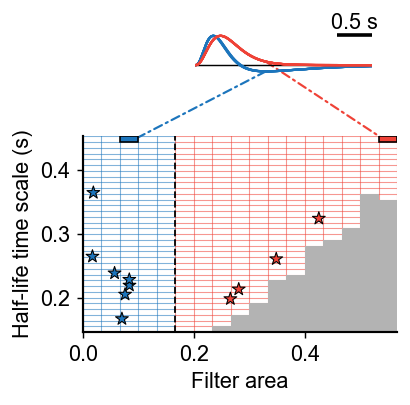

In [5]:
EXAMPLE_CELLS = {'double': (1, 49), 'single': (15, 49)}
LEADER_T = 1.0  # s, where a leader meets its filter
LEADER_LW = 1.2
LEADER_DASH = (4, 2, 1, 2)
T_SHOW = np.arange(0.001, 2.5, 0.001)
STAR_SIZE = 55


def lattice_frame(ax, lw=0.6, alpha=0.55):
    for k in range(min(K_GRID), max(K_GRID) + 2):
        ax.plot([LAT_A0 + k * LAT_DA] * 2, Y_AX, color=color_by_polarity[polarity_of_k(k)], lw=lw,
                alpha=alpha, zorder=0)
    for m in range(min(M_GRID), max(M_GRID) + 2):
        y = LAT_T0 + m * LAT_DT
        ax.plot([X_AX[0], A_BOUNDARY], [y, y], color=color_by_polarity['double'], lw=lw,
                alpha=alpha, zorder=0)
        ax.plot([A_BOUNDARY, X_AX[1]], [y, y], color=color_by_polarity['single'], lw=lw,
                alpha=alpha, zorder=0)
    for (k, m) in FORBIDDEN_CELLS:
        ax.add_patch(cell_rect(k, m, facecolor='0.7', edgecolor='none', zorder=1))
    ax.set_xlim(*X_AX); ax.set_ylim(*Y_AX)
    ax.set_xticks([0.0, 0.2, 0.4]); ax.set_yticks([0.2, 0.3, 0.4])


def leader(Fig, ax_from, xy_from, ax_to, xy_to, color, lw=LEADER_LW, dash=LEADER_DASH, **kw):
    # dash-dotted line ending on a full dash
    _pa = ax_from.transData.transform(xy_from)
    _pb = ax_to.transData.transform(xy_to)
    _L = np.hypot(*(_pb - _pa)) * 72.0 / Fig.dpi
    _off = (dash[0] * lw - _L) % (sum(dash) * lw)
    ax_from.add_artist(ConnectionPatch(
        xyA=xy_from, coordsA=ax_from.transData, xyB=xy_to, coordsB=ax_to.transData,
        color=color, lw=lw, ls=(_off / lw, dash), clip_on=False, **kw))


Fig = plt.figure(figsize=figsize_of('A'))
ax = Fig.add_axes(rect_in('A', *AXES['A']))
axf = Fig.add_axes(rect_in('A', *AXES['A_tr']))
lattice_frame(ax)
ax.axvline(A_BOUNDARY, color='k', ls='--', lw=1.0, zorder=5)
ax.scatter(A_fit, tau_fit, c=[color_by_polarity[polarity_of[ct]] for ct in CELL_TYPES],
           s=STAR_SIZE, marker='*', edgecolor='k', linewidth=0.6, zorder=6)
strip_spines(ax)
ax.set_xlabel('Filter area')
ax.set_ylabel('Half-life time scale (s)')

axf.axhline(0, color='k', lw=0.8, zorder=1)
_t0 = T_SHOW[-1] - 0.5
axf.plot([_t0, _t0 + 0.5], [1.02, 1.02], color='k', lw=2.0, solid_capstyle='butt')
axf.text(_t0 + 0.25, 1.10, '0.5 s', ha='center', va='bottom')
axf.set_xlim(0, T_SHOW[-1]); axf.set_ylim(-1.15, 1.55)
axf.set_axis_off()
for pol, (k, m) in EXAMPLE_CELLS.items():
    _hs = [filter_function(T_SHOW, *p) for p in gpar[(gk == k) & (gm == m)]]
    for _h in _hs:
        axf.plot(T_SHOW, _h, color=color_by_polarity[pol], lw=1.2, alpha=0.8, zorder=2)
    _it = np.searchsorted(T_SHOW, LEADER_T)
    cx, cy = cell_centre(k, m)
    leader(Fig, ax, (cx, cy - LAT_DT / 2), axf, (T_SHOW[_it], np.mean(_hs, axis=0)[_it]),
           color_by_polarity[pol], zorder=7)
    ax.add_patch(cell_rect(k, m, facecolor=color_by_polarity[pol], edgecolor='k',
                           linewidth=0.9, zorder=8))
Fig.savefig(PATH_PDF / 'Fig4A_FeatureSpace_Lattice.pdf', transparent=True)
plt.show()

## Fig. 4C

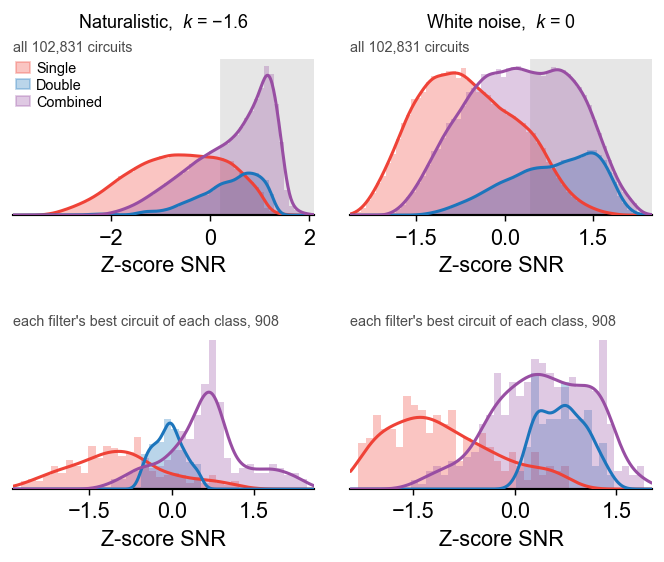

In [6]:
def best_of_each_circuits(c, a):
    # each filter's best circuit of its own class and its best combined circuit
    b_same, b_opp = best_partners(c, a)
    own = np.where(c.POL == 'double', CLASS_ORDER.index('DD'), CLASS_ORDER.index('SS'))
    return (np.concatenate([b_same, b_opp]),
            np.concatenate([own, np.full(c.N, CLASS_ORDER.index('SD'))]))


def figure_location(c, select, sel_name, n_bins=60, n_bins_eff=40):
    # z-score SNR: all circuits (top) and the selected circuits (bottom), per stimulus
    Fig, axs = plt.subplots(2, 2, figsize=(5.4, 4.3),
                            gridspec_kw=dict(height_ratios=[1, 1], hspace=0.75, wspace=0.12,
                                             left=0.07, right=0.98, top=0.88, bottom=0.11))
    for col, a in enumerate(STIMULI):
        y_eff, cat_eff = select(c, a)
        y_all = c.SNR[a][c.I, c.J]
        _pad = 0.03 * (y_eff.max() - y_eff.min())
        band = (y_eff.min() - _pad, y_eff.max() + _pad)
        _mu, _sd = y_all.mean(), y_all.std()
        band = tuple((b - _mu) / _sd for b in band)
        y_all = (y_all - _mu) / _sd
        y_eff = (y_eff - y_eff.mean()) / y_eff.std()
        _pad = 0.03 * (y_eff.max() - y_eff.min())
        rows = ((y_all, c.CAT, np.linspace(y_all.min(), y_all.max(), n_bins + 1),
                 f'all {len(y_all):,d} circuits'),
                (y_eff, cat_eff, np.linspace(y_eff.min() - _pad, y_eff.max() + _pad,
                                             n_bins_eff + 1),
                 f'{sel_name}, {len(y_eff):,d}'))
        for row, (y, cat, bins, name) in enumerate(rows):
            ax = axs[row, col]
            draw_class_hist(ax, y, cat, bins)
            ax.text(0.0, 1.03, name, transform=ax.transAxes, ha='left', va='bottom',
                    fontsize=8, color='0.3')
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.set_yticks([])
            ax.set_xlabel('Z-score SNR')
            strip_spines(ax, keep=('bottom',))
        axs[0, col].axvspan(*band, color='0.90', zorder=0)
        axs[0, col].set_title(f'Naturalistic,  $k$ = −{a:g}' if a else 'White noise,  $k$ = 0',
                              fontsize=10, pad=17)
    class_legend(axs[0, 0])
    return Fig


Fig = figure_location(CIRC, best_of_each_circuits, "each filter's best circuit of each class")
Fig.savefig(PATH_PDF / 'Fig4C_BestOfEachClass_ZScore.pdf', transparent=True)
plt.show()

## Fig. 4D

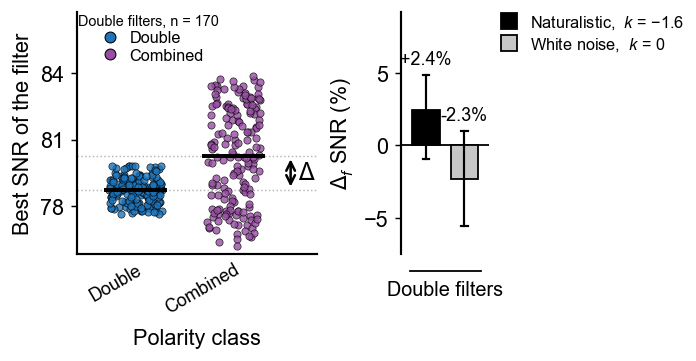

170 double-polarity filters, median Delta_f [95% block-bootstrap CI]:
  naturalistic: +2.44%  [-0.96, +4.85]
  white noise : -2.35%  [-5.55, +0.99]
  d_f = Delta_f(nat) - Delta_f(WN): +4.72 pp  [+3.02, +5.03]


In [7]:
BOOT_BLOCK, N_BOOT = 5, 4000  # block bootstrap: 5 x 5 lattice cells


def delta_f(c, a):
    # Delta_f (%): best combined over best same-polarity circuit of each filter
    b_same, b_opp = best_partners(c, a)
    return 100.0 * (b_opp / b_same - 1.0)


def block_ci(x, cells, block=BOOT_BLOCK, n_boot=N_BOOT, seed=3):
    # 95% interval of median(x), resampling block x block patches of lattice cells
    key = [tuple(k) for k in cells // block]
    patches = sorted(set(key))
    members = [np.flatnonzero([kk == u for kk in key]) for u in patches]
    rng = np.random.default_rng(seed)
    med = [np.median(x[np.concatenate([members[j] for j in
                                        rng.integers(0, len(patches), len(patches))])])
           for _ in range(n_boot)]
    return np.percentile(med, (2.5, 97.5))


c = CIRC
cells = np.array([lattice_cell(A, T) for A, T in zip(c.A, c.TAU)])
sel = c.POL == 'double'
dn, dw = delta_f(c, K_NAT)[sel], delta_f(c, K_WN)[sel]
d_f = dn - dw
ci = {a: block_ci(d, cells[sel]) for a, d in ((K_NAT, dn), (K_WN, dw))}

Fig = plt.figure(figsize=(5.6, 3.0))
axA = Fig.add_axes([0.13, 0.27, 0.33, 0.62])
_wB = 2.3 * (0.896 * SCALE / 4.9)
axB = Fig.add_axes([0.575, 0.27, _wB / 5.6, 0.62])

b_same, b_opp = best_partners(c, K_NAT)
rng = np.random.default_rng(0)
for gi, (vals, k) in enumerate(((b_same[sel], 'DD'), (b_opp[sel], 'SD'))):
    axA.plot(gi + rng.uniform(-0.27, 0.27, vals.size), vals, 'o', markersize=4.0,
             markerfacecolor=COLOR_CLASS[k], markeredgecolor='k', markeredgewidth=0.4,
             alpha=0.8, zorder=3, ls='none')
    axA.axhline(np.median(vals), color='0.7', lw=0.8, ls=':', zorder=1)
    axA.plot([gi - 0.30, gi + 0.30], [np.median(vals)] * 2, '-', color='k', lw=2.2, zorder=4)
axA.annotate('', xy=(1.58, np.median(b_opp[sel])), xytext=(1.58, np.median(b_same[sel])),
             arrowprops=dict(arrowstyle='<->', color='k', lw=1.4))
axA.text(1.66, 0.5 * (np.median(b_same[sel]) + np.median(b_opp[sel])), r'$\Delta$',
         fontsize=13, va='center', ha='left')
axA.set_xlim(-0.60, 1.85)
axA.set_xticks([0, 1])
axA.set_xticklabels([CLASS_LABEL['DD'], CLASS_LABEL['SD']], fontsize=10, rotation=30,
                    ha='right', rotation_mode='anchor')
axA.set_xlabel('Polarity class', labelpad=6)
axA.set_ylabel('Best SNR of the filter')
axA.yaxis.set_major_locator(MaxNLocator(nbins=4))
_y0, _y1 = axA.get_ylim()
axA.set_ylim(_y0, _y0 + (_y1 - _y0) * 1.30)
axA.tick_params(axis='x', length=0)
strip_spines(axA)
axA.legend(handles=[Line2D([], [], ls='none', marker='o', markersize=6,
                           markerfacecolor=COLOR_CLASS[k], markeredgecolor='k',
                           markeredgewidth=0.6, label=CLASS_LABEL[k]) for k in ('DD', 'SD')],
           loc='upper left', frameon=False, fontsize=9, handletextpad=0.2,
           labelspacing=0.15, borderpad=0.0, borderaxespad=0.1,
           title=f'Double filters, n = {int(sel.sum())}', title_fontsize=8)

xb = np.array([0.0, 1.0])
vals = [float(np.median(dn)), float(np.median(dw))]
cis = [ci[K_NAT], ci[K_WN]]
hi = 1.9 * max(max(vals), max(x[1] for x in cis))
lo = min(0.0, 1.35 * min(min(vals), min(x[0] for x in cis)))
span = hi - lo
axB.axhline(0, color='k', lw=1.0, zorder=2)
for x, a, v, (lo_ci, hi_ci) in zip(xb, STIMULI, vals, cis):
    axB.bar(x, v, width=0.72, color=COLOR_STIM[a], edgecolor='k', lw=1.0, zorder=3)
    axB.plot([x, x], [lo_ci, hi_ci], '-', color='k', lw=1.2, zorder=5)
    axB.plot([x - 0.08, x + 0.08], [lo_ci] * 2, '-', color='k', lw=1.2, zorder=5)
    axB.plot([x - 0.08, x + 0.08], [hi_ci] * 2, '-', color='k', lw=1.2, zorder=5)
    axB.text(x, max(v, hi_ci, 0.0) + 0.03 * span, f'{v:+.1f}%', ha='center', va='bottom',
             fontsize=10, zorder=4)
axB.set_xticks(xb); axB.set_xticklabels(['', ''])
axB.set_xlim(-0.65, 1.65)
axB.set_ylim(lo, hi)
axB.set_ylabel(r'$\Delta_f$ SNR (%)')
axB.yaxis.set_major_locator(MaxNLocator(nbins=4))
axB.tick_params(axis='x', length=0)
strip_spines(axB, keep=('left',))
axB.legend(handles=[Line2D([], [], ls='none', marker='s', markersize=9,
                           markerfacecolor=COLOR_STIM[a], markeredgecolor='k',
                           markeredgewidth=1.0,
                           label='Naturalistic,  $k$ = −1.6' if a else 'White noise,  $k$ = 0')
                    for a in STIMULI],
           loc='upper left', bbox_to_anchor=(1.04, 1.0), frameon=False, fontsize=9,
           handletextpad=0.25, labelspacing=0.2, borderpad=0.0, borderaxespad=0.0)
_tr = axB.get_xaxis_transform()
axB.plot([xb[0] - 0.42, xb[1] + 0.42], [-0.07] * 2, transform=_tr, color='k', lw=1.0,
         clip_on=False)
axB.text(xb.mean(), -0.11, 'Double filters', transform=_tr, ha='center', va='top', fontsize=11)
Fig.savefig(PATH_PDF / 'Fig4D_BestOfEachClass.pdf', transparent=True)
plt.show()

print(f'{int(sel.sum())} double-polarity filters, median Delta_f [95% block-bootstrap CI]:')
for nm, d, a in (('naturalistic', dn, K_NAT), ('white noise ', dw, K_WN)):
    print(f'  {nm}: {np.median(d):+.2f}%  [{ci[a][0]:+.2f}, {ci[a][1]:+.2f}]')
lo_ci, hi_ci = block_ci(d_f, cells[sel])
print(f'  d_f = Delta_f(nat) - Delta_f(WN): {np.median(d_f):+.2f} pp  [{lo_ci:+.2f}, {hi_ci:+.2f}]')

## Fig. 4E, F

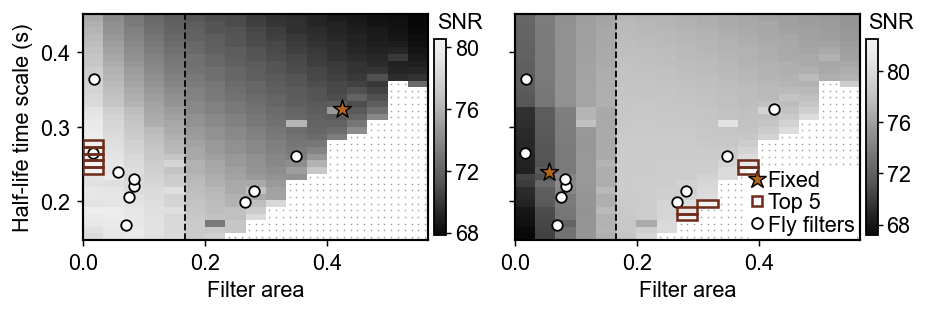

In [8]:
PANEL_TYPE = {'E': 'Mi4', 'F': 'Tm4'}
STAR_SIZE_EF = 110
LEGEND_IN = 'F'
TOP_N = 5
CELL_EX = np.array([LAT_A0 + k * LAT_DA for k in range(min(K_GRID), max(K_GRID) + 2)])
CELL_EY = np.array([LAT_T0 + m * LAT_DT for m in range(min(M_GRID), max(M_GRID) + 2)])


def snr_grid(row):
    g = np.full((len(M_GRID), len(K_GRID)), np.nan)
    for i in np.where(ELIG)[0]:
        g[ALL_M[i] - min(M_GRID), ALL_K[i] - min(K_GRID)] = row[i]
    return np.ma.masked_invalid(g)


def top_partners(row, exclude, n=TOP_N):
    cand = np.where(ELIG)[0]
    cand = cand[cand != exclude]
    return list(cand[np.argsort(-row[cand])][:n])


def stipple(ax, cells, zorder=2, ground='w', color=None):
    # forbidden cells: a grid of dots drawn as markers
    nx, ny = STIPPLE['per_cell']
    K = np.array([c[0] for c in cells], float)[:, None, None]
    M = np.array([c[1] for c in cells], float)[:, None, None]
    X = LAT_A0 + (K + ((np.arange(nx) + 0.5) / nx)[None, :, None]) * LAT_DA
    Y = LAT_T0 + (M + ((np.arange(ny) + 0.5) / ny)[None, None, :]) * LAT_DT
    X, Y = np.broadcast_arrays(X, Y)
    if ground is not None:
        for (k, m) in cells:
            ax.add_patch(cell_rect(k, m, facecolor=ground, edgecolor='none', zorder=zorder))
    ax.scatter(X.ravel(), Y.ravel(), s=STIPPLE['size'], marker='o',
               color=STIPPLE['color'] if color is None else color,
               linewidths=0, zorder=zorder + 0.1)


def draw_top(ax, members):
    for j in members:
        ax.add_patch(cell_rect(int(ALL_K[j]), int(ALL_M[j]), facecolor='none',
                               edgecolor=COLOR_BEST, linewidth=1.4, zorder=8))


def draw_landscape(ax, ct, vmin=None, vmax=None):
    row = landscape_row(ct)
    if vmin is None:
        vmin, vmax = float(row[ELIG].min()), float(row[ELIG].max())
    im = ax.pcolormesh(CELL_EX, CELL_EY, snr_grid(row), cmap=SNR_GREYS, vmin=vmin, vmax=vmax,
                       shading='flat', zorder=1, rasterized=True)
    stipple(ax, FORBIDDEN_CELLS)
    ax.axvline(A_BOUNDARY, color='k', ls='--', lw=1.0, zorder=5)
    rest = [i for i, c in enumerate(CELL_TYPES) if c != ct]
    ax.scatter(A_fit[rest], tau_fit[rest], s=34, marker='o', facecolor='w', edgecolor='k',
               linewidth=1.0, zorder=7)
    i_ct = CELL_TYPES.index(ct)
    ax.scatter([A_fit[i_ct]], [tau_fit[i_ct]], s=STAR_SIZE_EF, marker='*', facecolor=COLOR_FIXED,
               edgecolor='k', linewidth=0.8, zorder=10)
    ax.set_xlim(LAT_A0 + ALL_K[ELIG].min() * LAT_DA, X_AX[1])
    ax.set_ylim(LAT_T0 + ALL_M[ELIG].min() * LAT_DT, Y_AX[1])
    ax.set_xticks([0.0, 0.2, 0.4]); ax.set_yticks([0.2, 0.3, 0.4])
    ax.set_xlabel('Filter area')
    return im


Fig = plt.figure(figsize=figsize_of('EF'))
axes = {}
for b, ct in PANEL_TYPE.items():
    ax = axes[b] = Fig.add_axes(rect_in('EF', *AXES[b]))
    im = draw_landscape(ax, ct)
    draw_top(ax, top_partners(landscape_row(ct), MEAS_ROW[ct]))
    if b == 'E':
        ax.set_ylabel('Half-life time scale (s)')
    else:
        ax.tick_params(axis='y', labelleft=False)
    _x1, _yt, _yb = AXES[b][2], AXES[b][1], AXES[b][3]
    cax = Fig.add_axes(rect_in('EF', _x1 + CB_BOX[0], _yt + CB_BOX[1],
                               _x1 + CB_BOX[2], _yb + CB_BOX[3]))
    cb = Fig.colorbar(im, cax=cax)
    cb.locator = MaxNLocator(nbins=4); cb.update_ticks()
    cb.outline.set_linewidth(1.0)
    cax.tick_params(length=2.5, pad=2.5)
    Fig.text(*point_in('EF', _x1 + CB_BOX[0] + CB_TITLE[0], _yt + CB_TITLE[1]), 'SNR',
             ha='left', va='baseline')
_ms = np.sqrt(STAR_SIZE_EF)
axes[LEGEND_IN].legend(handles=[
    Line2D([], [], marker='*', ls='none', markerfacecolor=COLOR_FIXED, markeredgecolor='k',
           markeredgewidth=0.8, markersize=_ms, label='Fixed'),
    Line2D([], [], marker='s', ls='none', markerfacecolor='none',
           markeredgecolor=COLOR_BEST, markeredgewidth=1.4, markersize=6, label=f'Top {TOP_N}'),
    Line2D([], [], marker='o', ls='none', markerfacecolor='w', markeredgecolor='k',
           markeredgewidth=1.0, markersize=6, label='Fly filters')],
    loc='lower right', frameon=True, facecolor='w', edgecolor='none', framealpha=1.0,
    borderaxespad=0.1, borderpad=0.15, labelspacing=0.1, handlelength=0.6, handletextpad=0.2)
Fig.savefig(PATH_PDF / f"Fig4EF_SNRLandscape_{PANEL_TYPE['E']}_{PANEL_TYPE['F']}.pdf",
            transparent=True)
plt.show()

In [9]:
# best partners of each measured type
for ct in CELL_TYPES:
    top = top_partners(landscape_row(ct), MEAS_ROW[ct])
    n_opp = sum(ALL_POL[j] != polarity_of[ct] for j in top)
    print(f'{ct:4s} ({polarity_of[ct]}): {n_opp} of the {TOP_N} best partners of opposite polarity')

# SNR of each partner as a fraction of the maximum over the generalized space
THRESH = 0.95
rows_wn = {ct: _z[f'snr_a{K_WN:g}'][MEAS_ROW[ct]] for ct in CELL_TYPES}
frac_meas, frac_all, frac_opp, frac_meas_wn = {}, [], [], []
for ct in CELL_TYPES:
    adm = ELIG.copy(); adm[MEAS_ROW[ct]] = False
    opp = [MEAS_ROW[p] for p in CELL_TYPES if polarity_of[p] != polarity_of[ct]]
    row = landscape_row(ct)
    mx = row[adm].max()
    frac_meas[ct] = row[opp] / mx
    frac_all.append((row[adm] >= THRESH * mx).mean())
    frac_opp.append((row[adm & (ALL_POL != polarity_of[ct])] >= THRESH * mx).mean())
    frac_meas_wn.append(rows_wn[ct][opp] / rows_wn[ct][adm].max())
print(f'\nmeasured partners of opposite polarity: at least '
      f'{100 * min(f.min() for f in frac_meas.values()):.1f}% of the maximum for every type; '
      f'all >= {100 * THRESH:.0f}% for {sum((f >= THRESH).all() for f in frac_meas.values())} '
      f'of {len(CELL_TYPES)} types')
print(f'admissible partners >= {100 * THRESH:.0f}% of the maximum (median over types): '
      f'{100 * np.median(frac_all):.0f}% of all, {100 * np.median(frac_opp):.0f}% of the opposite class')
print(f'white noise: measured partners of opposite polarity >= {100 * THRESH:.0f}% of the maximum: '
      f'median over types {100 * np.median([(f >= THRESH).mean() for f in frac_meas_wn]):.0f}%, '
      f'{sum(int((f >= THRESH).sum()) for f in frac_meas_wn)} pairs in total')

L1   (double): 5 of the 5 best partners of opposite polarity
L2   (double): 5 of the 5 best partners of opposite polarity
L3   (single): 3 of the 5 best partners of opposite polarity
Mi1  (double): 5 of the 5 best partners of opposite polarity
Mi9  (single): 5 of the 5 best partners of opposite polarity
Tm3  (double): 5 of the 5 best partners of opposite polarity
Mi4  (single): 5 of the 5 best partners of opposite polarity
Tm2  (double): 5 of the 5 best partners of opposite polarity
Tm1  (double): 5 of the 5 best partners of opposite polarity
Tm4  (double): 5 of the 5 best partners of opposite polarity
Tm9  (single): 5 of the 5 best partners of opposite polarity

measured partners of opposite polarity: at least 93.6% of the maximum for every type; all >= 95% for 8 of 11 types
admissible partners >= 95% of the maximum (median over types): 27% of all, 44% of the opposite class
white noise: measured partners of opposite polarity >= 95% of the maximum: median over types 0%, 6 pairs in tota

## Fig. S5

78 empty cells; 46 excluded filters: 8 two-hump, 38 flat-top


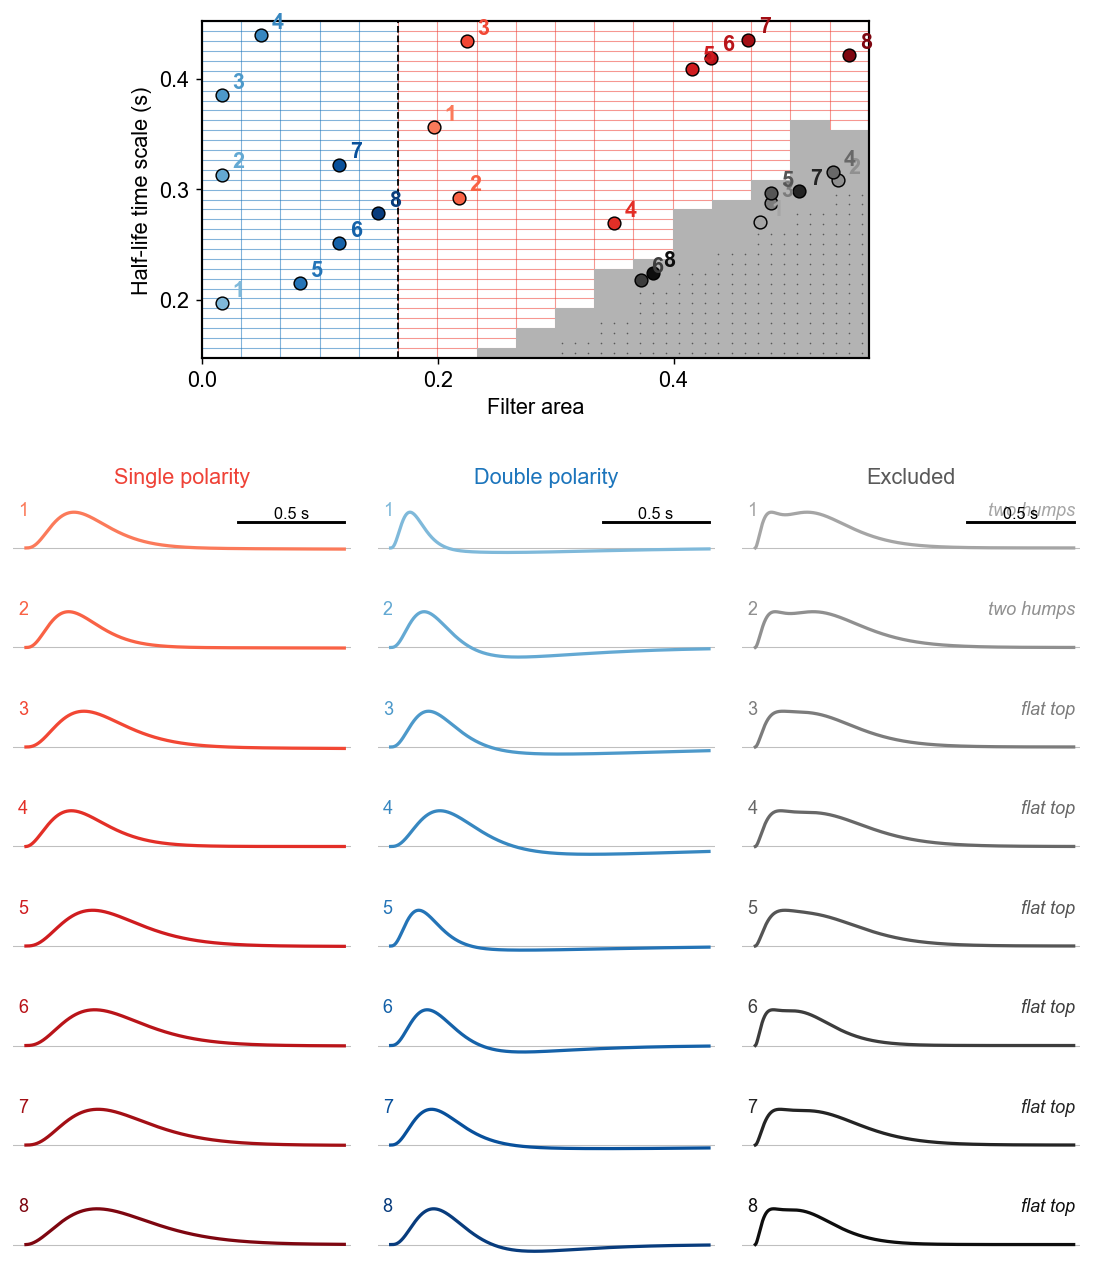

In [10]:
SAMPLE_N = 8
SAMPLE_SEED = 3
SAMPLE_COLS = ('single', 'double', 'excluded')
SAMPLE_HUMP = 2  # excluded examples with two humps
SAMPLE_CMAP = {'single': plt.cm.Reds, 'double': plt.cm.Blues, 'excluded': plt.cm.Greys}
SAMPLE_TITLE = {'single': 'Single polarity', 'double': 'Double polarity', 'excluded': 'Excluded'}
T_FILT, FILT_SCALE, FILT_FS = 1.5, 0.5, 9  # s, s, pt

FORBIDDEN_ROWS = np.array([i for i in range(N_ALL) if ALL_CELL[i] in set(FORBIDDEN_CELLS)])
print(f'{len(BAD_CELLS)} empty cells; {len(FORBIDDEN_ROWS)} excluded filters: '
      f'{int((~ALL_OK[FORBIDDEN_ROWS]).sum())} two-hump, {int(ALL_OK[FORBIDDEN_ROWS].sum())} flat-top')


def exclusion_reason(j):
    h = filter_function(t_fine, *ALL_PARS[j])
    if n_pos_peaks(h) != 1:
        return 'two humps'
    if h.min() <= -1e-3 and h.argmax() > h.argmin():
        return 'flipped'
    if peak_flatness(ALL_PARS[j]) > SHARP_MAX:
        return 'flat top'
    return 'below the floor'


def polarity_sample(n=SAMPLE_N, seed=SAMPLE_SEED):
    rng = np.random.default_rng(seed)
    out = {p: np.sort(rng.choice(np.where(ELIG & (ALL_POL == p))[0], n, replace=False))
           for p in ('single', 'double')}
    _hump = FORBIDDEN_ROWS[~ALL_OK[FORBIDDEN_ROWS]]
    _flat = FORBIDDEN_ROWS[ALL_OK[FORBIDDEN_ROWS]]
    _nh = min(SAMPLE_HUMP, n, len(_hump))
    out['excluded'] = np.concatenate([
        rng.choice(_hump, _nh, replace=False),
        rng.choice(_flat, n - _nh, replace=False)]).astype(int)
    return out


sel_s = polarity_sample()
shade = {p: SAMPLE_CMAP[p](np.linspace(0.45, 0.95, SAMPLE_N)) for p in SAMPLE_COLS}
Fig = plt.figure(figsize=(2.85 * len(SAMPLE_COLS), 9.8))
top, bot = Fig.subfigures(2, 1, height_ratios=[3.0, 6.0], hspace=0.02)

axf = top.add_subplot()
top.subplots_adjust(left=0.20, right=0.80, top=0.97, bottom=0.17)
lattice_frame(axf)
stipple(axf, BAD_CELLS, ground=None, color='0.35')
axf.axvline(A_BOUNDARY, color='k', ls='--', lw=1.0, zorder=5)
for p in SAMPLE_COLS:
    for r, j in enumerate(sel_s[p]):
        axf.scatter([ALL_A[j]], [ALL_TAU[j]], s=50, marker='o', facecolor=shade[p][r],
                    edgecolor='k', linewidth=0.8, zorder=9)
        axf.annotate(f'{r + 1}', (ALL_A[j], ALL_TAU[j]), textcoords='offset points',
                     xytext=(6, 4), color=shade[p][r], fontweight='bold', zorder=10)
axf.set_xlabel('Filter area')
axf.set_ylabel('Half-life time scale (s)')

axs = bot.subplots(SAMPLE_N, len(SAMPLE_COLS))
bot.subplots_adjust(left=0.03, right=0.99, top=0.93, bottom=0.02, hspace=0.45, wspace=0.08)
_m = t_fine <= T_FILT
for r in range(SAMPLE_N):
    for col, p in enumerate(SAMPLE_COLS):
        ax = axs[r, col]
        j = sel_s[p][r]
        _h = filter_function(t_fine, *ALL_PARS[j])
        ax.axhline(0.0, color='0.75', linewidth=0.6)
        ax.plot(t_fine[_m], _h[_m], color=shade[p][r], linewidth=1.8)
        strip_spines(ax, keep=())
        ax.tick_params(bottom=False, labelbottom=False, left=False, labelleft=False)
        ax.set_xlim(-0.06, T_FILT + 0.03)
        ax.set_ylim(min(-0.6, 1.15 * float(_h[_m].min())), 1.32)
        ax.text(0.015, 1.0, f'{r + 1}', transform=ax.transAxes, fontsize=10, ha='left',
                va='top', color=shade[p][r])
        if p == 'excluded':
            ax.text(0.985, 1.0, exclusion_reason(j), transform=ax.transAxes, fontsize=10,
                    ha='right', va='top', style='italic', color=shade[p][r])
        if r == 0:
            ax.set_title(SAMPLE_TITLE[p], pad=10,
                         color='0.35' if p == 'excluded' else color_by_polarity[p])
            ax.plot([T_FILT - FILT_SCALE, T_FILT], [0.72, 0.72], color='k', linewidth=1.6)
            ax.text(T_FILT - FILT_SCALE / 2, 0.75, f'{FILT_SCALE:g} s', ha='center',
                    va='bottom', fontsize=FILT_FS)
Fig.savefig(PATH_PDF / 'FigS5_GeneralizedFeatureSpace_FilterExamples.pdf', transparent=True)
plt.show()

## Fig. S6

A: 102,831 circuits


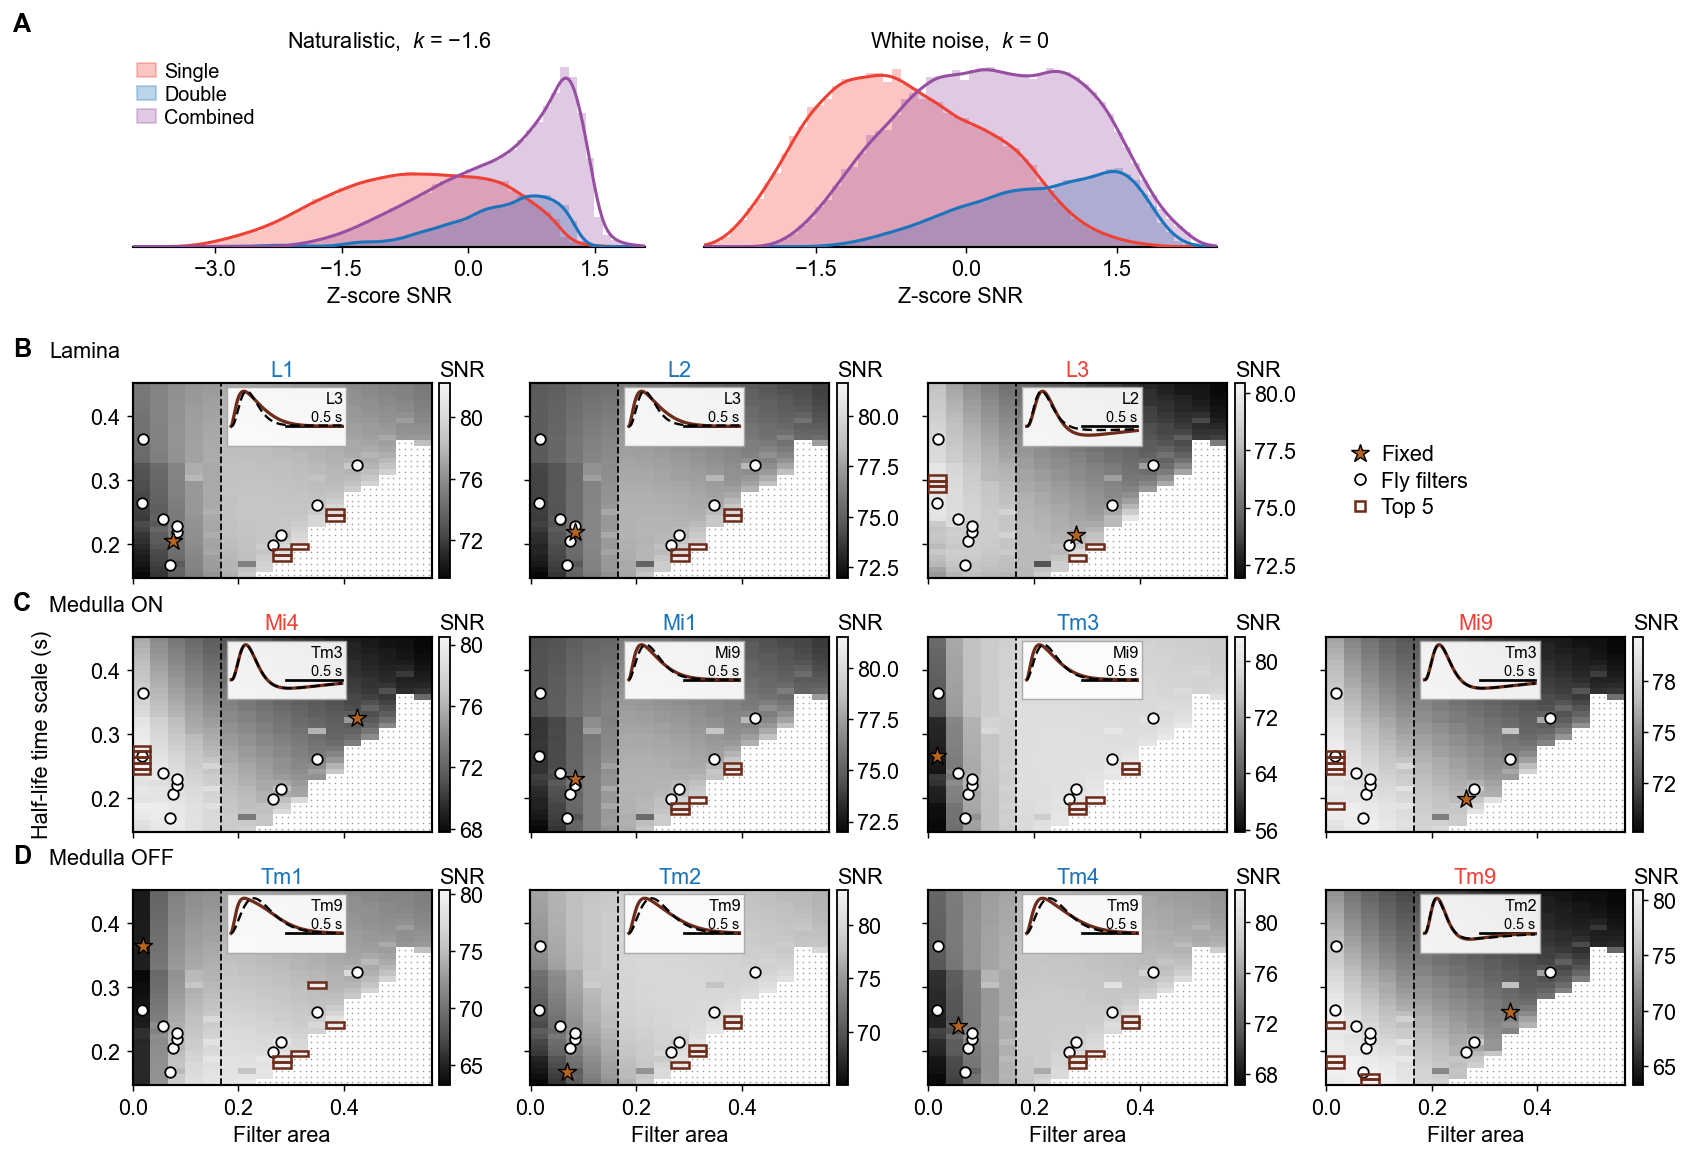

In [11]:
T_INSET = 1.0  # s
FILT_W, FILT_H = 0.40, 0.30  # inset size, axes fractions
FILT_PAD = 0.02
FILT_FS_SC = FILT_FS - 1

SUPP_ROWS = {'B': ('Lamina', ['L1', 'L2', 'L3']),
             'C': ('Medulla ON', ['Mi4', 'Mi1', 'Tm3', 'Mi9']),
             'D': ('Medulla OFF', ['Tm1', 'Tm2', 'Tm4', 'Tm9'])}
SUPP_W, SUPP_H = 2.30, 1.50  # inches
SUPP_GAP_X = 0.20
SUPP_CB_PAD = 0.06  # panel to its colorbar
SUPP_CB_W = 0.08
SUPP_CB_SPACE = SUPP_CB_PAD + SUPP_CB_W + 0.42  # colorbar + tick labels
SUPP_GAP_Y = 0.45
SUPP_HIST_H = 1.45
SUPP_HIST_GAP = 1.05
SUPP_HIST_SEP = 0.45
SUPP_RIGHT_W = 2 * (0.80 + 1.05)  # right of the histograms, left empty
SUPP_MARGIN = dict(left=1.00, right=0.15, bottom=0.62, top=0.55)


def nearest_measured(j, types=CELL_TYPES):
    _i = [CELL_TYPES.index(t) for t in types]
    d = np.hypot(A_fit[_i] - ALL_A[j], tau_fit[_i] - ALL_TAU[j])
    n = int(np.argmin(d))
    return types[n], float(d[n])


def closest_to_circuit(cells, types):
    # of the candidate cells, the one nearest to a measured filter of types
    return min(((j,) + nearest_measured(j, types) for j in cells), key=lambda r: r[2])


def draw_filters(ax, j, types=CELL_TYPES):
    # inset: filter of cell j (solid) and the nearest measured filter (dashed)
    ct_n, d_n = nearest_measured(j, types)
    _xl = ax.get_xlim()
    _x0 = (A_BOUNDARY - _xl[0]) / (_xl[1] - _xl[0]) + FILT_PAD
    axi = ax.inset_axes((_x0, 1 - FILT_PAD - FILT_H, min(FILT_W, 0.99 - _x0), FILT_H))
    axi.set_facecolor('w'); axi.patch.set_alpha(0.92)
    axi.patch.set_edgecolor('0.65'); axi.patch.set_linewidth(0.8)
    _m = t_fine <= T_INSET
    axi.plot(t_fine[_m], filter_function(t_fine, *fit_params[ct_n])[_m],
             color='k', linewidth=1.3, linestyle='--', dashes=(4, 2), zorder=4)
    axi.plot(t_fine[_m], filter_function(t_fine, *ALL_PARS[j])[_m],
             color=COLOR_BEST, linewidth=1.8, zorder=3)
    strip_spines(axi, keep=())
    axi.tick_params(bottom=False, labelbottom=False, left=False, labelleft=False)
    axi.set_xlim(-0.04, T_INSET + 0.04); axi.set_ylim(-0.55, 1.12)
    axi.plot([T_INSET - FILT_SCALE, T_INSET], [0.0, 0.0], color='k', linewidth=1.5, zorder=2)
    axi.text(T_INSET, 0.05, f'{FILT_SCALE:g} s', ha='right', va='bottom', fontsize=FILT_FS_SC)
    axi.text(0.98, 0.93, ct_n, transform=axi.transAxes, color='k', fontsize=FILT_FS,
             ha='right', va='top')
    return ct_n, d_n


def legend_landscape(ax, **kw):
    _ms = np.sqrt(STAR_SIZE_EF)
    opts = dict(loc='lower right', frameon=True, facecolor='w', edgecolor='none',
                framealpha=1.0, borderaxespad=0.1, borderpad=0.15, labelspacing=0.1,
                handlelength=0.6, handletextpad=0.2)
    opts.update(kw)
    return ax.legend(handles=[
        Line2D([], [], marker='*', ls='none', markerfacecolor=COLOR_FIXED, markeredgecolor='k',
               markeredgewidth=0.8, markersize=_ms, label='Fixed'),
        Line2D([], [], marker='o', ls='none', markerfacecolor='w', markeredgecolor='k',
               markeredgewidth=1.0, markersize=6, label='Fly filters'),
        Line2D([], [], marker='s', ls='none', markerfacecolor='none',
               markeredgecolor=COLOR_BEST, markeredgewidth=1.4, markersize=6,
               label=f'Top {TOP_N}')], **opts)


c, rows = CIRC, SUPP_ROWS
ncols, nrows = max(len(t) for _, t in rows.values()), len(rows)
m = SUPP_MARGIN
W = m['left'] + ncols * (SUPP_W + SUPP_CB_SPACE) + (ncols - 1) * SUPP_GAP_X + m['right']
H = (m['bottom'] + nrows * SUPP_H + (nrows - 1) * SUPP_GAP_Y + SUPP_HIST_GAP + SUPP_HIST_H
     + m['top'])
Fig = plt.figure(figsize=(W, H))
def box(x, y, w, h):  # inches
    return Fig.add_axes([x / W, y / H, w / W, h / H])
def col_x(j):
    return m['left'] + j * (SUPP_W + SUPP_CB_SPACE + SUPP_GAP_X)
def row_y(i):
    return m['bottom'] + (nrows - 1 - i) * (SUPP_H + SUPP_GAP_Y)


def letter(y_top, text, name=None):
    Fig.text(0.08 / W, (y_top + 0.17) / H, text, fontsize=14, weight='bold', va='bottom')
    if name:
        Fig.text(0.36 / W, (y_top + 0.17) / H, name, va='bottom')


# A: z-score SNR of all circuits
y_A = row_y(0) + SUPP_H + SUPP_HIST_GAP
w_A = (W - m['left'] - m['right'] - SUPP_HIST_SEP - SUPP_RIGHT_W) / 2
axA = []
for n, a in enumerate(STIMULI):
    ax = box(m['left'] + n * (w_A + SUPP_HIST_SEP), y_A, w_A, SUPP_HIST_H)
    y = c.SNR[a][c.I, c.J]
    z = (y - y.mean()) / y.std()
    draw_class_hist(ax, z, c.CAT, np.linspace(z.min(), z.max(), 61))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_yticks([])
    ax.set_xlabel('Z-score SNR')
    strip_spines(ax, keep=('bottom',))
    ax.set_title(f'Naturalistic,  $k$ = −{a:g}' if a else 'White noise,  $k$ = 0', pad=6)
    axA.append(ax)
class_legend(axA[0], fontsize=11)
letter(y_A + SUPP_HIST_H, 'A')
print(f'A: {len(c.CAT):,d} circuits')

# B-D: SNR landscapes, each on its own grey scale
for i, (b, (name, types)) in enumerate(rows.items()):
    for j, ct in enumerate(types):
        ax = box(col_x(j), row_y(i), SUPP_W, SUPP_H)
        im = draw_landscape(ax, ct)
        cax = box(col_x(j) + SUPP_W + SUPP_CB_PAD, row_y(i), SUPP_CB_W, SUPP_H)
        cb = Fig.colorbar(im, cax=cax)
        cb.locator = MaxNLocator(nbins=4); cb.update_ticks()
        cb.outline.set_linewidth(1.0)
        cax.tick_params(length=2.5, pad=2.5)
        cax.set_title('SNR', pad=4, loc='left')
        _tp = top_partners(landscape_row(ct), MEAS_ROW[ct])
        draw_top(ax, _tp)
        _js, _cs, _ = closest_to_circuit(_tp, [t for t in types if t != ct])
        draw_filters(ax, _js, types=[_cs])
        ax.set_title(ct, pad=4, color=color_by_polarity[ALL_POL[MEAS_ROW[ct]]])
        if j:
            ax.tick_params(labelleft=False)
        if i < nrows - 1:
            ax.tick_params(labelbottom=False)
            ax.set_xlabel('')
    letter(row_y(i) + SUPP_H, b, name)
Fig.text(0.30 / W, (row_y(nrows - 1) + row_y(0) + SUPP_H) / 2 / H,
         'Half-life time scale (s)', rotation=90, ha='center', va='center')

free = [(i, j) for i, (_, t) in enumerate(rows.values()) for j in range(len(t), ncols)]
i, j = free[0]
lax = box(col_x(j) + 0.15, row_y(i), SUPP_W - 0.15, SUPP_H)
lax.set_axis_off()
legend_landscape(lax, loc='center left', frameon=False, borderaxespad=0.0,
                 handlelength=1.0, handletextpad=0.5, labelspacing=0.3)
Fig.savefig(PATH_PDF / 'FigS6_AllCircuits_Landscapes.pdf', transparent=True)
plt.show()